In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
students = pd.read_csv("../data/students.csv")
attendance = pd.read_csv("../data/attendance.csv")
timetable = pd.read_csv("../data/timetable.csv")
subjects = pd.read_csv("../data/subjects.csv")
calendar = pd.read_csv("../data/academic_calendar.csv")
lab_batches = pd.read_csv("../data/lab_batches.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
print("Students:", students.shape)
print("Attendance:", attendance.shape)
print("Timetable:", timetable.shape)
print("Subjects:", subjects.shape)
print("Calendar:", calendar.shape)
print("Lab batches:", lab_batches.shape)

Students: (200, 9)
Attendance: (80732, 15)
Timetable: (50, 8)
Subjects: (7, 5)
Calendar: (80, 4)
Lab batches: (200, 6)


In [5]:
display(students.head())
display(attendance.head())
display(timetable.head())

,student_id,semester,branch,section,synthetic_attendance_persona,latent_base_attendance_probability,commute_time_minutes,previous_semester_attendance_pct,previous_cgpa_synthetic
0,S001,5,CSE (AI-ML),B,occasional_bunker,0.822,45,89.0,8.87
1,S002,5,CSE (AI-ML),B,occasional_bunker,0.763,10,69.2,7.45
2,S003,5,CSE (AI-ML),B,occasional_bunker,0.865,60,74.8,7.21
3,S004,5,CSE (AI-ML),B,occasional_bunker,0.769,15,84.9,9.00
4,S005,5,CSE (AI-ML),B,regular,0.924,60,90.0,6.99


,student_id,date,day,time_slot,slot_number,subject_code,subject_name,session_type,lab_batch,attendance_status,present_label,days_to_nearest_exam,is_exam_nearby,attendance_threshold_pct,synthetic_data
0,S001,2026-08-03,Monday,10:10-11:00,2,IoTA,IoT & Automation,Practical/Programming,NaN,Present,1,42,0,80,1
1,S001,2026-08-03,Monday,12:10-13:00,4,MLE,Machine Learning Essentials,Theory,NaN,Absent,0,42,0,80,1
2,S001,2026-08-03,Monday,13:10-14:00,5,CS,Cyber Security,Theory,NaN,Absent,0,42,0,80,1
3,S001,2026-08-03,Monday,15:10-16:00,7,DC,Distributed Computing,Theory,NaN,Present,1,42,0,80,1
4,S001,2026-08-03,Monday,16:10-17:00,8,DC,Distributed Computing,Lab,B3,Present,1,42,0,80,1


,day,time_slot,slot_number,subject_code,subject_name,session_type,applicable_batch,notes
0,Monday,10:10-11:00,2,IoTA,IoT & Automation,Practical/Programming,All,NaN
1,Monday,12:10-13:00,4,MLE,Machine Learning Essentials,Theory,All,NaN
2,Monday,13:10-14:00,5,CS,Cyber Security,Theory,All,NaN
3,Monday,15:10-16:00,7,DC,Distributed Computing,Theory,All,NaN
4,Monday,16:10-17:00,8,MLE,Machine Learning Essentials,Lab,B1,Parallel lab group; applies only to assigned b...


In [6]:
print("Attendance information:")
attendance.info()

print("\nMissing values:")
print(attendance.isnull().sum())

print("\nDuplicate attendance records:")
print(attendance.duplicated().sum())

Attendance information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80732 entries, 0 to 80731
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   student_id                80732 non-null  object
 1   date                      80732 non-null  object
 2   day                       80732 non-null  object
 3   time_slot                 80732 non-null  object
 4   slot_number               80732 non-null  int64 
 5   subject_code              80732 non-null  object
 6   subject_name              80732 non-null  object
 7   session_type              80732 non-null  object
 8   lab_batch                 26732 non-null  object
 9   attendance_status         80732 non-null  object
 10  present_label             80732 non-null  int64 
 11  days_to_nearest_exam      80732 non-null  int64 
 12  is_exam_nearby            80732 non-null  int64 
 13  attendance_threshold_pct  80732 non-null  int64 
 14

In [7]:
overall_attendance = attendance["present_label"].mean() * 100

print(f"Overall synthetic attendance: {overall_attendance:.2f}%")

Overall synthetic attendance: 79.66%


subject_name
Business Models Canvas         82.00
Cyber Security                 80.68
Foundations of AI              80.45
Distributed Computing          80.09
IoT & Automation               79.25
Machine Learning Essentials    78.89
Theory of Computation          78.03
Name: present_label, dtype: float64


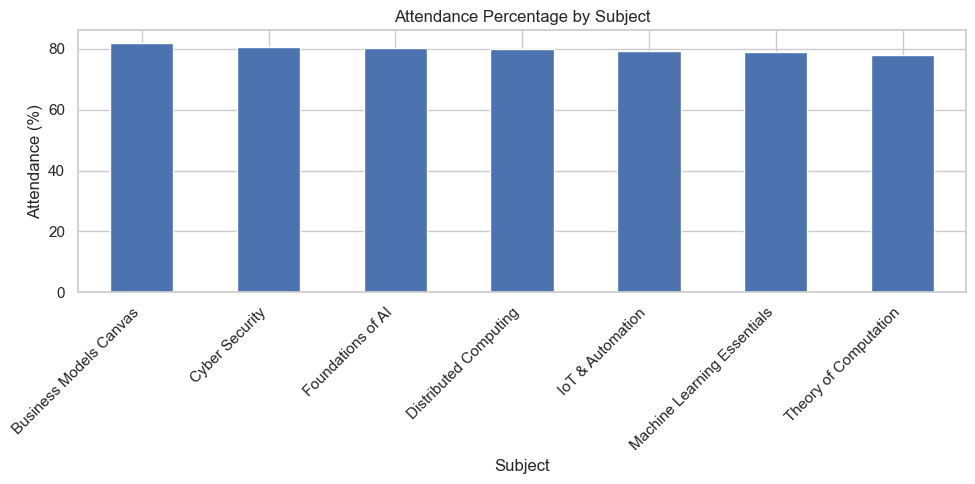

In [8]:
subject_attendance = (
    attendance.groupby("subject_name")["present_label"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(subject_attendance.round(2))

subject_attendance.plot(kind="bar", figsize=(10, 5))
plt.title("Attendance Percentage by Subject")
plt.xlabel("Subject")
plt.ylabel("Attendance (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

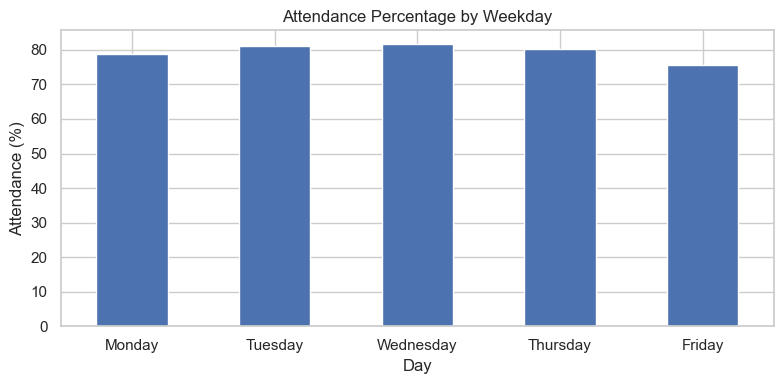

In [9]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

day_attendance = (
    attendance.groupby("day")["present_label"]
    .mean()
    .reindex(day_order)
    .mul(100)
)

day_attendance.plot(kind="bar", figsize=(8, 4))
plt.title("Attendance Percentage by Weekday")
plt.xlabel("Day")
plt.ylabel("Attendance (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

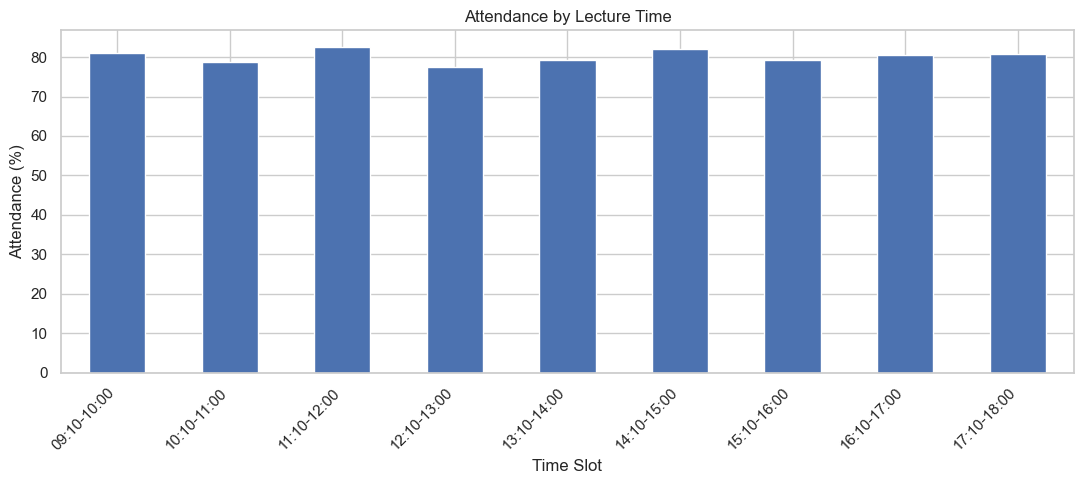

In [10]:
time_attendance = (
    attendance.groupby("time_slot")["present_label"]
    .mean()
    .mul(100)
)

time_attendance.plot(kind="bar", figsize=(11, 5))
plt.title("Attendance by Lecture Time")
plt.xlabel("Time Slot")
plt.ylabel("Attendance (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
student_attendance = (
    attendance.groupby("student_id")["present_label"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

student_attendance.columns = [
    "student_id",
    "lectures_attended",
    "total_lectures",
    "attendance_ratio"
]

student_attendance["attendance_percentage"] = (
    student_attendance["attendance_ratio"] * 100
)

student_attendance["status"] = np.where(
    student_attendance["attendance_percentage"] >= 80,
    "Meeting threshold",
    "Below threshold"
)

display(student_attendance.head(10))

print("\nStudent attendance status:")
print(student_attendance["status"].value_counts())

,student_id,lectures_attended,total_lectures,attendance_ratio,attendance_percentage,status
0,S001,325,400,0.812500,81.250000,Meeting threshold
1,S002,295,400,0.737500,73.750000,Below threshold
2,S003,352,404,0.871287,87.128713,Meeting threshold
3,S004,335,416,0.805288,80.528846,Meeting threshold
4,S005,363,400,0.907500,90.750000,Meeting threshold
5,S006,331,416,0.795673,79.567308,Below threshold
6,S007,372,404,0.920792,92.079208,Meeting threshold
7,S008,318,412,0.771845,77.184466,Below threshold
8,S009,256,404,0.633663,63.366337,Below threshold
9,S010,291,400,0.727500,72.750000,Below threshold



Student attendance status:
status
Meeting threshold    104
Below threshold       96
Name: count, dtype: int64
